<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Tugas

Ketentuan: (1) pilih dataset nyata dari `sklearn.datasets`, (2) lakukan klasterisasi dengan HDBSCAN, (3) laporkan jumlah klaster, jumlah noise, dan visualisasi (PCA/t-SNE bila perlu), (4) analisis apakah hasilnya sesuai dengan label asli.

Dataset utama yang dipilih: **Iris** (150 sampel, 4 fitur, 3 spesies). Sebagai pembanding tambahan dipakai **Digits** (1797 sampel, 64 fitur, 10 kelas).

### 1. Memuat dataset Iris

In [19]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn import metrics

iris = load_iris()
Xi, yi = iris.data, iris.target
print('Bentuk data:', Xi.shape)
print('Kelas      :', list(iris.target_names))

Bentuk data: (150, 4)
Kelas      : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


### 2. Klasterisasi dengan HDBSCAN

In [21]:
import hdbscan

def ringkas(labels):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    return n_clusters, n_noise

hdb_iris = hdbscan.HDBSCAN(min_cluster_size=5).fit(Xi)
lab_i = hdb_iris.labels_

n_cl, n_ns = ringkas(lab_i)
print('Jumlah klaster:', n_cl)
print('Jumlah noise  :', n_ns)
print('Ukuran tiap klaster:', {int(k): int((lab_i == k).sum()) for k in sorted(set(lab_i))})

Jumlah klaster: 2
Jumlah noise  : 0
Ukuran tiap klaster: {0: 50, 1: 100}


### 3. Visualisasi dengan PCA (4 dimensi menjadi 2 dimensi)

Variansi yang dijelaskan PC1+PC2: 0.978


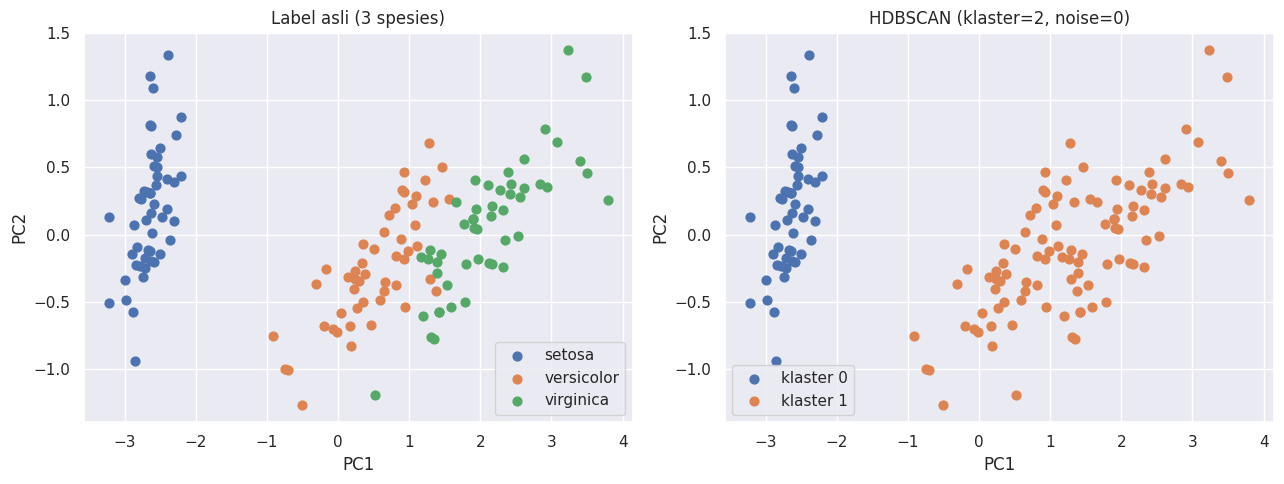

In [22]:
pca = PCA(n_components=2, random_state=0)
Zi = pca.fit_transform(Xi)
print('Variansi yang dijelaskan PC1+PC2:', round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, nama in enumerate(iris.target_names):
    ax[0].scatter(Zi[yi == k, 0], Zi[yi == k, 1], label=nama, s=40)
ax[0].set(title='Label asli (3 spesies)', xlabel='PC1', ylabel='PC2'); ax[0].legend()

for k in sorted(set(lab_i)):
    m = lab_i == k
    if k == -1:
        ax[1].scatter(Zi[m, 0], Zi[m, 1], c='k', marker='x', s=60, label='noise')
    else:
        ax[1].scatter(Zi[m, 0], Zi[m, 1], s=40, label=f'klaster {k}')
ax[1].set(title=f'HDBSCAN (klaster={n_cl}, noise={n_ns})', xlabel='PC1', ylabel='PC2'); ax[1].legend()
plt.tight_layout()
plt.show()

### 4. Kesesuaian dengan label asli

In [23]:
print(pd.crosstab(pd.Series(iris.target_names[yi], name='Spesies'),
                  pd.Series(lab_i, name='Klaster HDBSCAN')))
print()
print(f'Homogeneity : {metrics.homogeneity_score(yi, lab_i):.3f}')
print(f'Completeness: {metrics.completeness_score(yi, lab_i):.3f}')
print(f'V-measure   : {metrics.v_measure_score(yi, lab_i):.3f}')
print(f'ARI         : {metrics.adjusted_rand_score(yi, lab_i):.3f}')
print(f'AMI         : {metrics.adjusted_mutual_info_score(yi, lab_i):.3f}')

Klaster HDBSCAN   0   1
Spesies                
setosa           50   0
versicolor        0  50
virginica         0  50

Homogeneity : 0.579
Completeness: 1.000
V-measure   : 0.734
ARI         : 0.568
AMI         : 0.732


**Analisis:**

- **Hasil.** HDBSCAN (`min_cluster_size=5`) pada Iris menemukan **2 klaster** dan **0 noise**. Klaster 0 berisi 50 data dan klaster 1 berisi 100 data.
- **Kesesuaian dengan label asli.** Tabel silang menunjukkan klaster 0 identik dengan seluruh 50 data *setosa*, sedangkan klaster 1 menggabungkan seluruh *versicolor* dan *virginica*. Jadi hasil **sesuai sebagian**: setosa terpisah sempurna (Completeness = 1,000, tidak ada spesies yang terpecah), tetapi jumlah klaster (2) tidak sama dengan jumlah spesies (3) sehingga Homogeneity hanya 0,579, V-measure 0,734, ARI 0,568, dan AMI 0,732.
